* **Analysis Topic:** Analyzing popularity metrics, song durations, and chronological trends within Billy Joel's musical catalog based on his historical songs and album data.

* **Project Objectives:**
  * To develop practical data processing, cleaning, and analysis skills in Python using the Pandas library.
  * To identify patterns and key attributes that characterize the artist's most successful songs.
  * To create clear, professionally designed visual elements to present data-driven insights effectively.

* **Research Questions:**
  1. What are the top 10 most popular songs in the dataset, and which albums achieve the highest average popularity scores?
  2. Is there a correlation between a song's duration (length) and its overall popularity index?
  3. How have the average popularity and song lengths evolved across the different decades of the artist's career?

* **Tools and Techniques:**
  * **Pandas:** For data ingestion, initial inspection, filtering, aggregations (`groupby`), and computing descriptive statistics (mean, median, standard deviation).
  * **Matplotlib & Seaborn:** For generating five distinct types of diagnostic charts (e.g., scatter plots, histograms, and bar charts) to clearly illustrate data findings.


In [44]:
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt

In this phase, we load the dataset into a Pandas DataFrame and perform an initial review of its structure, columns, and data types.

**Column Descriptions:**
* `song_title`: The title of the song (String).
* `album_name`: The name of the album the song belongs to (String).
* `release_year`: The year the song/album was released (Integer).
* `popularity`: The popularity score of the song on a scale of 0 to 100 (Integer).
* `duration_ms`: The duration of the song measured in milliseconds (Integer).


In [46]:
df=pd.read_csv('songs.csv')

In [47]:
df.head()

,song_title,album_name,release_year,popularity,duration_ms
0,Zanzibar,52nd Street,1978,58,315000
1,Allentown,The Nylon Curtain,1982,68,232000
2,Until the Night,52nd Street,1978,53,415000
3,When in Rome,Storm Front,1989,38,284000
4,All You Wanna Do Is Dance,Turnstiles,1976,40,220000


In [48]:
df.tail()

,song_title,album_name,release_year,popularity,duration_ms
110,It's Still Rock and Roll to Me,Glass Houses,1980,73,177000
111,Two Thousand Years,River of Dreams,1993,42,310000
112,Somewhere Along the Line,Piano Man,1973,36,286000
113,This Night,An Innocent Man,1983,61,257000
114,A Room of Our Own,The Nylon Curtain,1982,41,240000


In [49]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 115 entries, 0 to 114
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   song_title    115 non-null    str  
 1   album_name    115 non-null    str  
 2   release_year  115 non-null    int64
 3   popularity    115 non-null    int64
 4   duration_ms   115 non-null    int64
dtypes: int64(3), str(2)
memory usage: 4.6 KB


In [50]:
df.describe()

,release_year,popularity,duration_ms
count,115.00000,115.000000,115.000000
mean,1980.60000,51.921739,253852.173913
std,7.69461,14.547049,61577.257632
min,1971.00000,27.000000,120000.000000
25%,1974.00000,41.000000,213500.000000
50%,1980.00000,48.000000,245000.000000
75%,1986.00000,61.500000,285000.000000
max,2024.00000,86.000000,457000.000000


In [51]:
df.shape

(115, 5)

In this phase, we prepare the dataset for deeper analysis by checking for integrity issues and applying essential data transformations. 

**Steps Applied:**
1. **Missing Values Check:** Verifying if there are any null values that require imputation or removal.
2. **Data Transformation:** Converting the song duration from milliseconds (`duration_ms`) to minutes (`duration_min`) and seconds(`duration_sec`) for better readability.
3. **Feature Engineering:** Creating a new `decade` column based on the `release_year` to analyze historical musical eras.


In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 115 entries, 0 to 114
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   song_title    115 non-null    str  
 1   album_name    115 non-null    str  
 2   release_year  115 non-null    int64
 3   popularity    115 non-null    int64
 4   duration_ms   115 non-null    int64
dtypes: int64(3), str(2)
memory usage: 4.6 KB


In [55]:
df = df[df['album_name']!='Single']

In [56]:
total_seconds = df['duration_ms'] // 1000 #Converting milliseconds to seconds by dividing by 1,000
df['minutes'] = (total_seconds // 60).astype(str) #creating a minutes column by dividing "total_seconds" by 60 to get just the number of minutes of the songs(without seconds)(it will be useful to create a column that shows the exact duration of the songs in minues)
df['seconds'] = (total_seconds % 60).astype(str) #creating a seconds column by % "total_seconds by 60 to get just the number of seconds for the songs(without minutes)(it will be useful to create a column that shows the exact duration of the songs in minues)
single_digit_seconds = (total_seconds % 60) < 10 #Creating a Boolean variable   that checks whether the seconds remaining beyond the completed minutes is less than 10
df.loc[single_digit_seconds, 'seconds'] = "0" + df['seconds']#Update the seconds column by adding 0 before numbers less than 10(it will be useful to create a column that shows the exact duration of the songs in minues)
df['duration_min'] = df['minutes'] + ":" + df['seconds'] #Creating the "Duration_min" column by connecting the Minutes column and the Seconds column to show the duration of the songs(in minutes,type str)
df['duration_sec'] = df['duration_ms'] // 1000 #Creating a "Duration_sec" column by dividing the duration_ms column by 1000 to show the duration of the songs(in seconds,type int)

In [57]:
df = df.drop(columns=['duration_ms', 'minutes', 'seconds'])

In [58]:
df['decade'] = (df['release_year'] // 10) * 10

In [59]:
df = df[['song_title', 'album_name', 'release_year', 'decade', 'popularity', 'duration_min', 'duration_sec']]

In [60]:
df

,song_title,album_name,release_year,decade,popularity,duration_min,duration_sec
0,Zanzibar,52nd Street,1978,1970,58,5:15,315
1,Allentown,The Nylon Curtain,1982,1980,68,3:52,232
2,Until the Night,52nd Street,1978,1970,53,6:55,415
3,When in Rome,Storm Front,1989,1980,38,4:44,284
4,All You Wanna Do Is Dance,Turnstiles,1976,1970,40,3:40,220
...,...,...,...,...,...,...,...
110,It's Still Rock and Roll to Me,Glass Houses,1980,1980,73,2:57,177
111,Two Thousand Years,River of Dreams,1993,1990,42,5:10,310
112,Somewhere Along the Line,Piano Man,1973,1970,36,4:46,286
113,This Night,An Innocent Man,1983,1980,61,4:17,257


In [62]:
df.shape

(114, 7)

In [63]:
df.describe()

,release_year,decade,popularity,duration_sec
count,114.000000,114.000000,114.000000,114.000000
mean,1980.219298,1975.964912,51.763158,253.973684
std,6.551037,6.479279,14.511090,61.835274
min,1971.000000,1970.000000,27.000000,120.000000
25%,1974.000000,1970.000000,41.000000,213.250000
50%,1980.000000,1980.000000,48.000000,246.500000
75%,1985.250000,1980.000000,61.000000,285.500000
max,1993.000000,1990.000000,86.000000,457.000000


In [64]:
df.sort_values('popularity').iloc[0]

song_title      You Look So Good to Me
album_name          Cold Spring Harbor
release_year                      1971
decade                            1970
popularity                          27
duration_min                      2:29
duration_sec                       149
Name: 86, dtype: object

In [65]:
df.popularity.min()

np.int64(27)

In [66]:
df.sort_values('popularity', ascending=False).iloc[0]

song_title            Vienna
album_name      The Stranger
release_year            1977
decade                  1970
popularity                86
duration_min            3:34
duration_sec             214
Name: 88, dtype: object

In [67]:
df.sort_values('duration_sec').iloc[0]

song_title                 Souvenir
album_name      Streetlife Serenade
release_year                   1974
decade                         1970
popularity                       41
duration_min                   2:00
duration_sec                    120
Name: 41, dtype: object

In [68]:
df.sort_values('duration_sec', ascending=False).iloc[0]

song_title      Scenes from an Italian Restaurant
album_name                           The Stranger
release_year                                 1977
decade                                       1970
popularity                                     78
duration_min                                 7:37
duration_sec                                  457
Name: 32, dtype: object

In [69]:
max_popularity=df.sort_values('popularity', ascending=False).drop_duplicates('album_name')#Creating a variable "a" that sorts the data base by popularity(from highest to lowest)and removes all the rows except the first one of each album
max_popularity=max_popularity.sort_values('release_year')#Creating a variable "b" that sorts "a" by release_year
max_popularity[['album_name','song_title','popularity']]#Showing the album_name song_title and popularity columns

,album_name,song_title,popularity
8,Cold Spring Harbor,She's Got a Way,65
85,Piano Man,Piano Man,85
6,Streetlife Serenade,The Entertainer,50
101,Turnstiles,New York State of Mind,72
88,The Stranger,Vienna,86
59,52nd Street,My Life,70
69,Glass Houses,You May Be Right,76
1,The Nylon Curtain,Allentown,68
57,An Innocent Man,Uptown Girl,83
37,The Bridge,This Is the Time,61


In [71]:
average_popularity=df.groupby('album_name')[['popularity']].mean()#Showing the average popularity of each album
average_popularity.sort_values('popularity',ascending=False)#Sorting the average popularity of each album from highest to lowest

,popularity
album_name,
The Stranger,71.000000
An Innocent Man,62.100000
Turnstiles,57.000000
52nd Street,56.333333
Storm Front,55.200000
Glass Houses,54.700000
The Bridge,50.000000
River of Dreams,49.700000
The Nylon Curtain,49.000000


In [72]:
df.groupby('decade')[['duration_sec']].mean()

,duration_sec
decade,
1970,249.625000
1980,253.020833
1990,282.900000


In [82]:
df.groupby('decade')[['popularity']].mean()

,popularity
decade,
1970,49.875000
1980,54.395833
1990,49.700000


In [73]:
d=df.groupby(['album_name','release_year']).agg(
    total_songs=('song_title', 'count'),
    avg_popularity=('popularity', 'mean'),
    max_popularity=('popularity', 'max')
)
d.sort_values('avg_popularity', ascending=False)#Sorting the average popularity of each album from higest to lowest

,,total_songs,avg_popularity,max_popularity
album_name,release_year,,,
The Stranger,1977,9,71.000000,86
An Innocent Man,1983,10,62.100000,83
Turnstiles,1976,8,57.000000,72
52nd Street,1978,9,56.333333,70
Storm Front,1989,10,55.200000,81
Glass Houses,1980,10,54.700000,76
The Bridge,1986,9,50.000000,61
River of Dreams,1993,10,49.700000,71
The Nylon Curtain,1982,9,49.000000,68


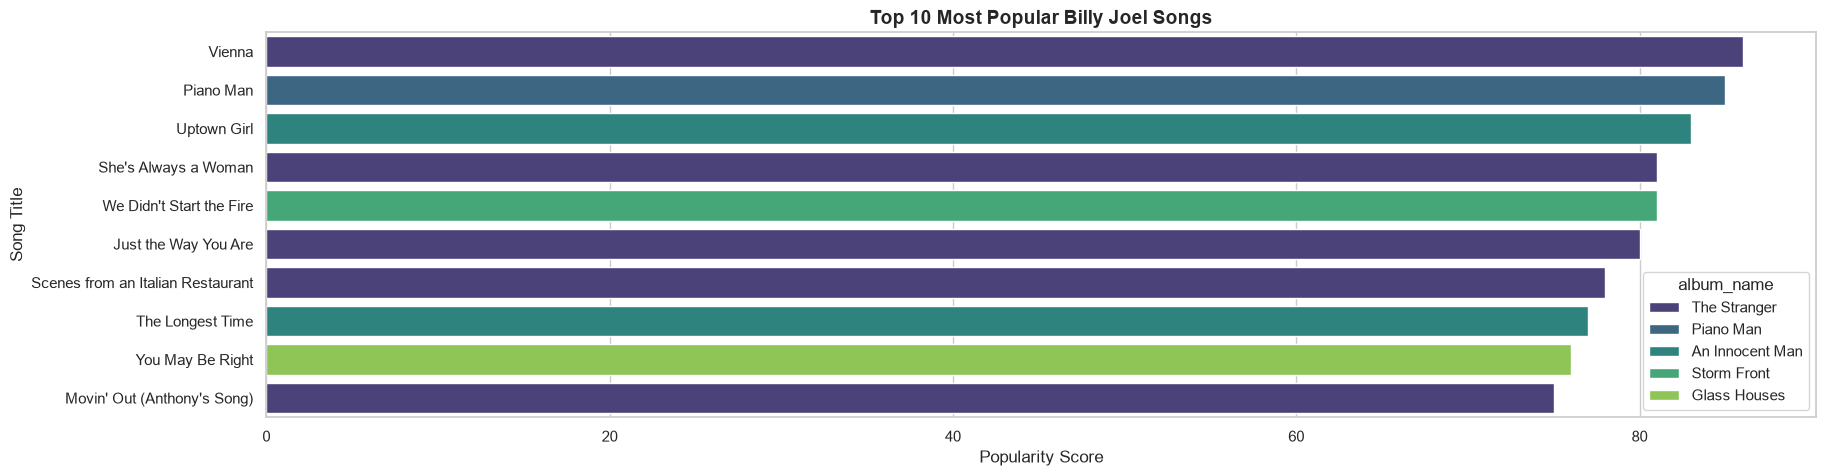

In [75]:
top_10_songs = df.sort_values('popularity', ascending=False).head(10)#Setting a variable that searches for the 10 most popular songs from all the songs
plt.figure(figsize=(20, 5))#Setting the graph to a size of 20x5
sb.barplot(data=top_10_songs, x='popularity', y='song_title',hue='album_name', palette='viridis')#Creating a barplot by Using the "top_10_songs" variable , defining the x-axis as the popularity, defining the y-axis as song_title, and defining the palette as viridis
plt.title('Top 10 Most Popular Billy Joel Songs', fontsize=14, fontweight='bold')#Giving the graph a title(size 14 bold)
plt.xlabel('Popularity Score', fontsize=12)#Giving the X row a title(size 12)
plt.ylabel('Song Title', fontsize=12)#Giving the Y row a title(size 12)
plt.show()#Showing the graph without any code
   

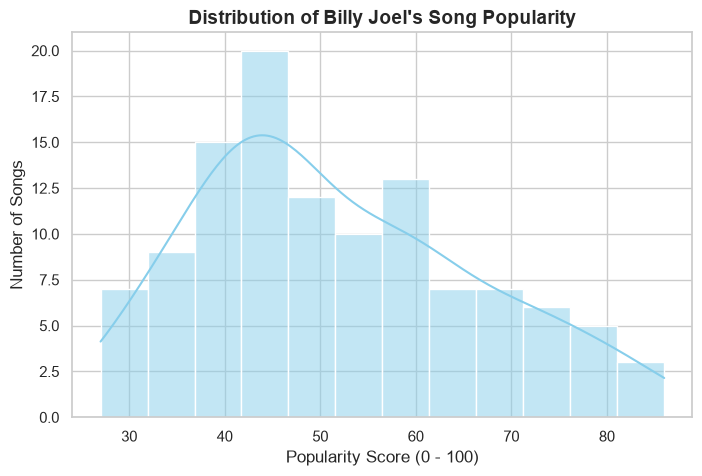

In [76]:
plt.figure(figsize=(8, 5))#Set the graph to a size of 8 x 5
sb.set_style("whitegrid")#Graph Design as whitegrid
sb.histplot(df['popularity'], bins=12, kde=True, color='skyblue')#Taking the popularity column, dividing it into 12 groups, adding an outline to the graph and coloring it skyblue
plt.title('Distribution of Billy Joel\'s Song Popularity', fontsize=14, fontweight='bold')#Giving the graph a title(size 14 bold)
plt.xlabel('Popularity Score (0 - 100)', fontsize=12)#Giving the X row a title(size 12)
plt.ylabel('Number of Songs', fontsize=12)#Giving the Y row a title(size 12)
plt.show()#Showing the graph without any code

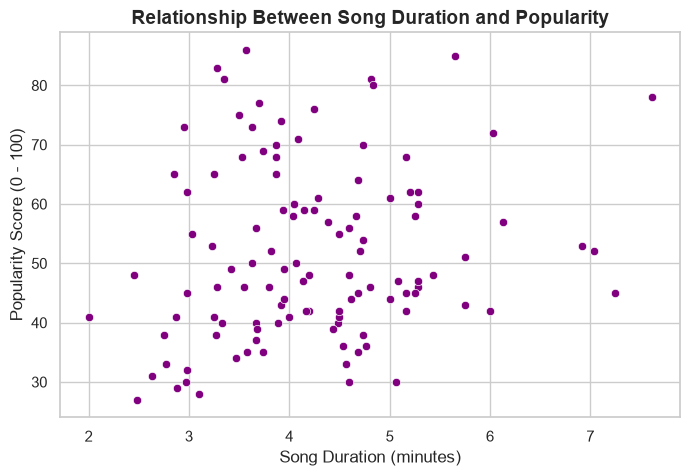

In [77]:
plt.figure(figsize=(8, 5))#Set the graph to a size of 8x5
sb.set_style("whitegrid")#Graph Design as whitegrid
sb.scatterplot(data=df, x='duration_sec', y='popularity', color='purple' )#Creating a scatterplot by Using the songs database, defining the x-axis as the duration in minutes, defining the y-axis as popularity, and define the color as purple
plt.title('Relationship Between Song Duration and Popularity', fontsize=14, fontweight='bold')#Giving the graph a title(size 14 bold)
plt.xlabel('Song Duration (minutes)', fontsize=12)#Giving the X row a title(size 12)
plt.ylabel('Popularity Score (0 - 100)', fontsize=12)#Giving the Y row a title(size 12)
plt.xticks([120,180,240,300,360,420],labels=['2','3','4','5','6','7'])#Changing the X marks to minutes
plt.show()#Showing the graph without any code

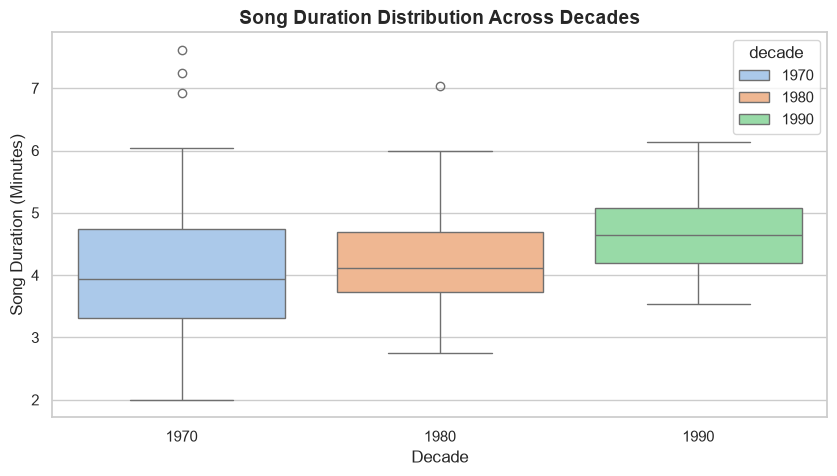

In [78]:
plt.figure(figsize=(10, 5))#Setting the graph to a size of 10x5
sb.boxplot(data=df, x='decade', y='duration_sec',hue='decade',palette='pastel')#Creating a boxplot by Using the songs database, defining the x-axis as the dacate, defining the y-axis as duration_sec,defining the hue as decade and defining the palette as viridis
plt.title('Song Duration Distribution Across Decades', fontsize=14, fontweight='bold')#Giving the graph a title(size 14 bold)  
plt.xlabel('Decade', fontsize=12)#Giving the X axis a title(size 12)
plt.ylabel('Song Duration (Minutes)', fontsize=12)#Giving the Y axis a title(size 12)
plt.yticks([120,180,240,300,360,420],labels=['2','3','4','5','6','7'])#Changing the Y marks to minutes
plt.show()#Showing the graph without any code

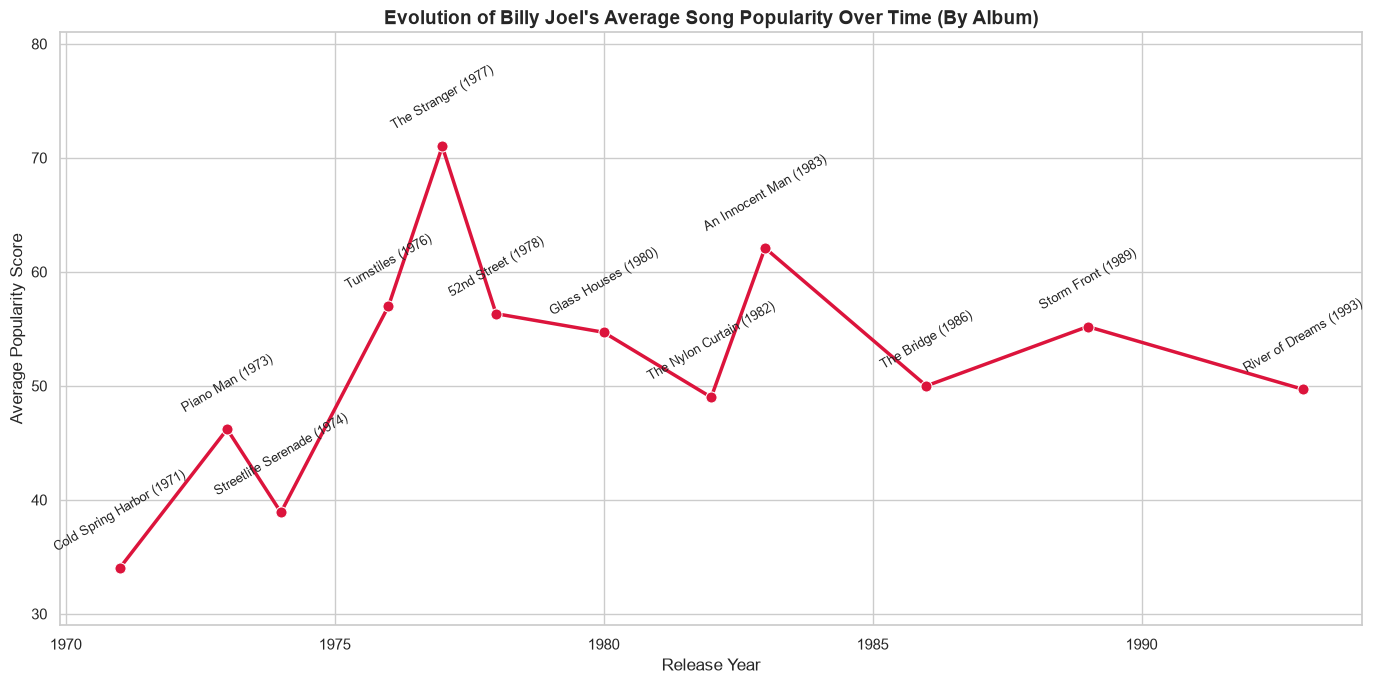

In [79]:
yearly_album_pop = df.groupby(['release_year', 'album_name'])[['popularity']].mean().reset_index()#Creating a variable "yearly_album_pop" that shows the average popularity by album/release year and numbering the rows with consecutive numbers starting from 0 
yearly_album_pop = yearly_album_pop.sort_values('release_year')#Sorting the variable "yearly_album_pop" by average popularity of each album from highest to lowest
plt.figure(figsize=(14, 7))#Set the graph to a size of 14x7
sb.set_theme(style="whitegrid")#Graph Design as whitegrid
sb.lineplot(data=yearly_album_pop, x='release_year', y='popularity', marker='o', color='crimson', linewidth=2.5, markersize=8)#Creating a linplot by using the "yearly_album_pop" variable,defining the x-axis as the release_year, defining the y-axis as popularity, defining the marker of the graph as cyrcle and defining the color as crimson 
for index, row in yearly_album_pop.iterrows():#Going through all the rows of the variable "yearly_album_pop" by a loop that in each turn of the loop you get information about one line (in order)
    label_text = f"{row['album_name']} ({int(row['release_year'])})"#Creating a variable that shows the album's name and year of release as follows:"album_name(release_year)"
    plt.text(x=row['release_year'], #Adding text to the graph at the X-axis position of the release year
             y=row['popularity'] + 1.5, #Positionning the Y axis 1.5 units above the position of the popularity (to ensure the text doesn't overlap the point)
             s=label_text, #The text itself is defined by the variable "label_text"
             fontsize=9, #setingthe text as size of 9
             rotation=30,  #rotation 30 degrees (to ensure readability and prevent the text labels from overlapping  
             ha='center') #centering the text to align perfectly above the point of each release year."  
plt.ylim(yearly_album_pop['popularity'].min() - 5, yearly_album_pop['popularity'].max() + 10)#configuring the Y axix range from 5 units below the lowest song average to 10 units above the highest song average (ensuring all text labels remain fully inside the plot boundary and are not cut off at the top or bottom).
plt.title('Evolution of Billy Joel\'s Average Song Popularity Over Time (By Album)', fontsize=14, fontweight='bold')#Giving the graph a title(size 14 bold)
plt.xlabel('Release Year', fontsize=12)#Giving the X row a title(size 12)
plt.ylabel('Average Popularity Score', fontsize=12)#Giving the Y row a title(size 12)
plt.tight_layout()#Verifing that all text values are inside the graph
plt.show()#Showing the graph without any code






**The success of Billy Joel's albums over the years**

It can be inferred from the lineplot that at the beginning of Billy Joel's career, during his first three albums in the early 1970's, his success was not particularly high(The only exception is the song "Piano Man", which was much more successful than the other songs from those years). However, starting from 1976 with the album Turnstiles, the average popularity consistently holds between 50 and 60 (The notable exception is the album The Stranger, which achieved a significantly higher average popularity of over 70 compared to the rest). This steady trend continues until his final album, River of Dreams, released in 1993 (some albums fall slightly below 50 or rise just above 60, these represent minor fluctuations, such as 49 or 62 according to the "average_popularity" table).From the album The Stranger, which holds the highest average popularity, it is evident that 5 out of Billy Joel's top 10 most popular songs belong to this single album. Another prominent album featured in the top 10 is An Innocent Man, driven by the hit songs 'Uptown Girl' and 'The Longest Time'. This album also ranks second overall in average popularity, leading to the inference that these two highly successful songs significantly contributed to its higher average compared to the remaining albums (with the exception of The Stranger).




**Correlation between song duration and popularity**


As shown in the scatter plot, the majority of the songs are not particularly long (under 5 minutes), and from 5 minutes onwards, the number of songs gradually decreases. In terms of popularity, it appears that most of the popular tracks (popularity above 70) are relatively short (under 5 minutes). There are only 3 prominent long songs (over 5 minutes) that stand out with high popularity scores above 70.
The songs with the highest popularity scores consistently cluster between 3 and 5 minutes. From a commercial standpoint, digital streaming platforms (like Spotify or Apple Music) and radio stations looking to optimize audience retention should prioritize tracks within this duration. It provides enough depth for artistic development without causing listener fatigue.



**Evolution of Song Duration Across Decades**

Based on the chronological distribution of song lengths across the decades, we can observe clear shifts in Billy Joel's musical approach:

* **The Experimental 1970s:** 
  The 1970s represent a decade of great structural variety. During this era, Billy Joel did not adhere to a strict time limit. While he wrote standard-length songs, he simultaneously experimented with highly compact songs alongside long, complex musical epics. This shows a high level of artistic freedom and structural diversity early in his career.

* **The Radio-Friendly 1980s:** 
  In the 1980s, the data shows a clear shift toward consistency and commercial standardization. While the middle duration of his tracks stayed similar to the 1970s, the wide gaps between his shortest and longest songs narrowed significantly. His musical output became highly uniform, focusing heavily on tight, radio-friendly pop and rock formats with very few structural surprises.

* **The Mature 1990s:** 
  The 1990s mark a noticeable evolution, as his songs became longer on average. The overall baseline of his song lengths shifted upward, moving away from quick pop structures.



**Evolution of Popularity Across Decades**


**The Formative 1970s (The Rise):** 
  The data shows that the 1970s marked the launch of his commercial breakthrough. While his earliest works from 1971 (Cold Spring Harbor) maintain a lower popularity baseline today, his career experienced a sharp upward trajectory in the late 1970s. This surge was primarily driven by iconic, high-scoring masterpiece tracks such as "Piano Man" (1973) and the release of the album The Stranger (1977), which features legendary songs like "Vienna" and "She's Always a Woman".

**The Commercial Peak of the 1980s (Sustained Success):** 
  The 1980s represent the absolute peak of Billy Joel's sustained global success, with the overall popularity scores consistently averaging between 50 and 60. During this decade, almost every album released maintained a highly stable baseline. This era produced explosive, chart-topping hits that remain massive cultural staples today, including "Uptown Girl", "We Didn't Start the Fire", and "You May Be Right".

**The Maturity of the 1990s (Legacy Era):** 
  In the 1990s, the volume of songs released began to decrease as the artist transitioned into a mature phase of his career. However, songs from this era, like "The River of Dreams" (1993), still secured highly respectable popularity scores. This demonstrates that his audience remained loyal and that his 1990s catalog successfully consolidated his status as a permanent legacy artist.
